In [1]:
# Load Data

import pandas as pd

TRI = "Triase/Triase/"
HIS = "Riwayat Medis/Riwayat Medis/"

KEY = "encounter_id"
PASIEN = "patient_id"
TARGET, ID = "target_class", "sample_id"
SEED, N_FOLD = 42, 5



In [2]:
# --- tabel utama ---
train = pd.read_csv("train.csv")
test  = pd.read_csv("test.csv")
index_enc = pd.read_csv("index_encounters.csv")
patients  = pd.read_csv("patients.csv")

base = pd.concat([train, test], ignore_index=True)

waktu = pd.read_csv("index_encounters.csv")
waktu["prediction_time"] = pd.to_datetime(waktu["prediction_time"], utc=True)
base = base.merge(waktu[[KEY, "prediction_time"]], on=KEY, how="left")
assert base[KEY].is_unique and base["prediction_time"].notna().all()


# EDA — mengenal data dari nol

Bagian ini menjelajahi data **tanpa asumsi sebelumnya**. Kita mulai dari pertanyaan sederhana, lalu membiarkan data yang menjawab:

1. Tabel apa saja yang ada, dan bagaimana kuncinya terhubung?
2. Seperti apa target (seimbang atau tidak)?
3. Bagaimana kualitas tiap tabel: nilai kosong, nilai janggal, format yang tidak seragam?
4. Bagaimana sebaran tiap variabel, dan apakah train mirip test?
5. Variabel mana yang tampak berhubungan dengan target, dan seberapa kuat dibandingkan kebetulan?
6. Apakah ada risiko kebocoran waktu pada tabel riwayat?

Aturan main: hubungan dengan target hanya dihitung di **train**; test hanya dipakai untuk memeriksa apakah ia mirip train.
Setiap temuan ditulis dari output di atasnya, dan bila masih berupa dugaan akan disebut sebagai dugaan.

### 0. Apa yang dikatakan dokumentasi?
Sebelum membuka data, baca kamus datanya. Tabel-tabel dimuat sekaligus supaya bisa diperiksa satu per satu.

In [3]:
# ===== 0. Persiapan: muat SEMUA tabel + kamus data =====
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, kruskal, ks_2samp
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 120)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

kamus     = pd.read_csv("DATA_DICTIONARY.csv")
vitals    = pd.read_csv(TRI + "triage_vitals.csv")
symptoms  = pd.read_csv(TRI + "triage_symptoms.csv")
severity  = pd.read_csv(TRI + "triage_symptom_severity.csv")
complaints = pd.read_csv(TRI + "presenting_complaints.csv")
hist = {n: pd.read_csv(HIS + f"{n}.csv") for n in
        ["previous_encounter", "conditions", "observations", "medications", "procedures", "immunizations", "allergies"]}

tabel = {"train": train, "test": test, "index_encounters": index_enc, "patients": patients,
         "presenting_complaints": complaints, "triage_vitals": vitals, "triage_symptoms": symptoms,
         "triage_symptom_severity": severity, **hist}

print("== Kamus data: peran kolom ==")
print(kamus["model_role"].value_counts().to_string())
print("\nCatatan yang ada di kamus:", kamus["notes"].unique().tolist())
print("\nKolom bukan 'candidate predictor':")
print(kamus[kamus["model_role"] != "candidate predictor / metadata"].groupby(["model_role", "file"])["column"].apply(list).to_string())

== Kamus data: peran kolom ==
model_role
candidate predictor / metadata    53
join only                         32
target (train only)                2

Catatan yang ada di kamus: ['Data grain and timing matter; do not infer modeling type from pandas dtype alone.']

Kolom bukan 'candidate predictor':
model_role           file                       
join only            allergies.csv                     [patient_id, history_encounter_id]
                     conditions.csv                    [patient_id, history_encounter_id]
                     immunizations.csv                 [patient_id, history_encounter_id]
                     index_encounters.csv                      [patient_id, encounter_id]
                     medications.csv                   [patient_id, history_encounter_id]
                     observations.csv                  [patient_id, history_encounter_id]
                     patients.csv                                            [patient_id]
                   

**Temuan.** Kamus mendefinisikan 87 kolom di 16 file. Sebanyak 32 kolom berperan `join only` (semua kolom kunci), 2 kolom adalah target (hanya ada di `train.csv` dan templat `sample_submission.csv`), dan 53 sisanya kandidat prediktor.
Semua baris kamus membawa catatan yang sama: *grain dan waktu penting, jangan menebak tipe dari dtype pandas.* Peringatan ini patut diingat: kamus menandai `income_at_visit` sebagai "campuran teks/angka" dan kolom `value` di vitals dan observations sebagai "campuran angka/teks", jadi isinya perlu diperiksa, bukan dipercaya begitu saja.

### 1. Seberapa besar tiap tabel, dan di mana nilai kosongnya?

In [4]:
# ===== 1. Inventaris tabel: ukuran, nilai kosong, baris duplikat =====
inv = []
for nama, d in tabel.items():
    kosong = (d.isna().mean() * 100).round(1)
    inv.append({"tabel": nama, "baris": len(d), "kolom": d.shape[1], "baris_duplikat": int(d.duplicated().sum()),
                "kolom_berkosong": {k: v for k, v in kosong[kosong > 0].items()}})
inv = pd.DataFrame(inv).set_index("tabel")
print(inv.to_string())

                         baris  kolom  baris_duplikat                                                                                                          kolom_berkosong
tabel                                                                                                                                                                         
train                     3600      4               0                                                                                                                       {}
test                      1400      3               0                                                                                                                       {}
index_encounters          5000      3               0                                                                                                                       {}
patients                  5000     10               0  {'age_at_visit': 1.2, 'ethnicity': 2.9, 'city': 42.3, 'county': 10.2, 

**Temuan.**
- Ada 16 tabel; yang terbesar `observations` (55.648 baris).
- Nilai kosong ada di `patients` (city 42%, marital 36%, county 10%, income 9%, ethnicity 3%, umur 1%), `triage_vitals.value` (11,1%), `severity_score` (4,6%), dan kolom nama di tabel riwayat (4–9%).
- Baris duplikat persis hanya muncul di `observations` (895), `procedures` (329), dan `medications` (79).
- `allergies` hanya berisi 2 baris, dan hanya milik 1 pasien.

### 2. Bagaimana kunci menghubungkan tabel?
Apakah satu sampel = satu pasien = satu encounter? Tabel mana yang punya banyak baris per pasien?

In [5]:
# ===== 2. Kunci & relasi antar tabel =====
# Pertanyaan: tabel mana yang 1 baris per pasien, mana yang banyak baris per pasien/encounter?
rel = []
for nama, d in tabel.items():
    r = {"tabel": nama}
    if PASIEN in d: g = d.groupby(PASIEN).size(); r.update(pasien_unik=len(g), baris_per_pasien_med=g.median(), baris_per_pasien_maks=g.max())
    if KEY in d:    r.update(encounter_unik=d[KEY].nunique())
    rel.append(r)
print(pd.DataFrame(rel).set_index("tabel").fillna("-").to_string())

semua = pd.concat([train, test])
print("\npasien sama di train & test      :", len(set(train[PASIEN]) & set(test[PASIEN])))
print("sampel_id unik / patient_id unik / encounter_id unik:", semua[ID].is_unique, semua[PASIEN].is_unique, semua[KEY].is_unique)
print("pasangan (patient, encounter) di train+test == index_encounters:",
      set(zip(semua[PASIEN], semua[KEY])) == set(zip(index_enc[PASIEN], index_enc[KEY])))
print("pasien di patients.csv == pasien di train+test:", set(patients[PASIEN]) == set(semua[PASIEN]))
for n in ["previous_encounter", "conditions", "observations", "medications", "procedures", "immunizations", "allergies"]:
    print(f"{n:20s} pasien di luar train+test: {len(set(hist[n][PASIEN]) - set(semua[PASIEN]))}")

                         pasien_unik  baris_per_pasien_med  baris_per_pasien_maks encounter_unik
tabel                                                                                           
train                           3600                   1.0                      1         3600.0
test                            1400                   1.0                      1         1400.0
index_encounters                5000                   1.0                      1         5000.0
patients                        5000                   1.0                      1              -
presenting_complaints           5000                   1.0                      1         5000.0
triage_vitals                   5000                   6.0                      6         5000.0
triage_symptoms                 5000                   4.0                     12         5000.0
triage_symptom_severity         4961                   3.0                     11         4961.0
previous_encounter            

**Temuan.**
- Train, test, index_encounters, patients, dan presenting_complaints semuanya **tepat satu baris per pasien**; pasangan (pasien, encounter) di train+test identik dengan `index_encounters`. Tidak ada pasien yang muncul di train sekaligus test.
- Tabel triase berbentuk **long**: `triage_vitals` tepat 6 baris per encounter, `triage_symptoms` 1–12 baris (median 4), `triage_symptom_severity` mencakup 4.961 dari 5.000 encounter.
- Tabel riwayat **tidak lengkap**: hanya sebagian pasien punya data (mis. observations 1.895 pasien dengan median 33 baris dan maksimum 309; conditions 2.222 pasien). Pasien tanpa riwayat adalah keadaan normal, bukan kesalahan data.
- Semua pasien di tabel riwayat ada di train+test.

### 3. Seperti apa targetnya?

                   jumlah  persen
target_class                     
viral_sinusitis      1480    41.1
viral_pharyngitis     985    27.4
acute_bronchitis      940    26.1
strep_pharyngitis     195     5.4
rasio kelas terbanyak : tersedikit = 7.6 | akurasi bila selalu menebak kelas terbanyak: 0.411


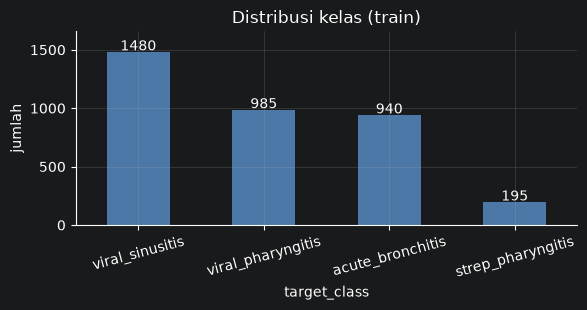

In [6]:
# ===== 3. Target =====
vc = train[TARGET].value_counts()
print(pd.DataFrame({"jumlah": vc, "persen": (vc / len(train) * 100).round(1)}))
print("rasio kelas terbanyak : tersedikit =", round(vc.max() / vc.min(), 1),
      "| akurasi bila selalu menebak kelas terbanyak:", round(vc.iloc[0] / len(train), 3))
ax = vc.plot.bar(color="#4C78A8", figsize=(6, 3.2), rot=15)
ax.set_title("Distribusi kelas (train)"); ax.set_ylabel("jumlah"); ax.set_ylim(0, vc.max() * 1.12)
for i, v in enumerate(vc.values): ax.text(i, v + 15, f"{v}", ha="center")
plt.tight_layout(); plt.show()

kelas_pasien = train.set_index(PASIEN)[TARGET]       # peta pasien -> kelas (hanya train)
kelas_enc    = train.set_index(KEY)[TARGET]          # peta encounter -> kelas

**Temuan.** Ada 4 kelas yang tidak seimbang: `viral_sinusitis` 41,1%, `viral_pharyngitis` 27,4%, `acute_bronchitis` 26,1%, dan `strep_pharyngitis` hanya 5,4% (195 baris). Rasio kelas terbanyak terhadap tersedikit 7,6.
Menebak kelas terbanyak saja sudah memberi akurasi 0,411, jadi akurasi mudah menipu di sini, apalagi untuk kelas kecil seperti strep.

### 4. Profil tabel `patients`
Bagaimana sebaran tiap kolom, dan apakah formatnya seragam? (Untuk teks, angka diganti `9` dan huruf `a` agar bentuknya terlihat.)

                   count unique                    top  freq       mean  min    max
patient_id          5000   5000  Pf4006ec4e7cd1bf39de6     1        NaN  NaN    NaN
age_at_visit      4940.0    NaN                    NaN   NaN  42.513745  0.0  999.0
gender              5000      2                      F  2645        NaN  NaN    NaN
race                5000      6                  white  4104        NaN  NaN    NaN
ethnicity           4856      2            nonhispanic  4332        NaN  NaN    NaN
city                2884    520                 Boston   252        NaN  NaN    NaN
county              4492     58       Middlesex County  1065        NaN  NaN    NaN
state               5000      1          Massachusetts  5000        NaN  NaN    NaN
income_at_visit     4545   4488               131587.0     3        NaN  NaN    NaN
marital_at_visit    3193      8                      M  1852        NaN  NaN    NaN

bentuk nilai income_at_visit:
income_at_visit
99999.9        2335
999999.9 

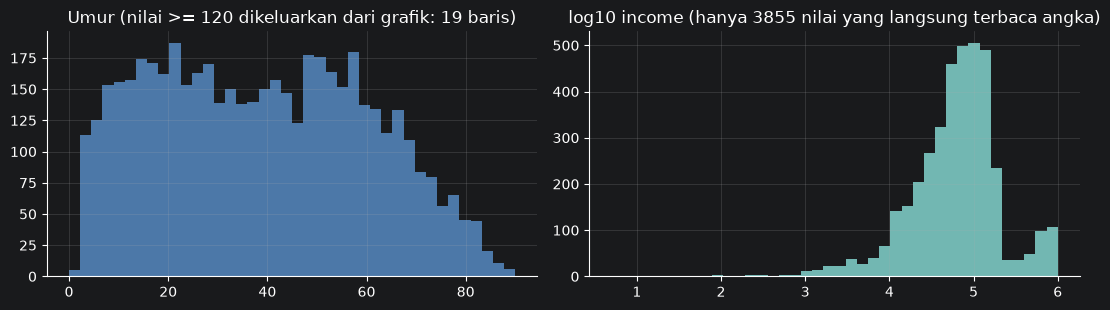

In [7]:
# ===== 4. patients: profil tiap kolom =====
print(patients.describe(include="all").T[["count", "unique", "top", "freq", "mean", "min", "max"]].to_string())

# bentuk teks: ganti angka -> 9 dan huruf -> a, untuk melihat apakah format seragam
def bentuk(s):
    return s.dropna().astype(str).str.replace(r"\d", "9", regex=True).str.replace(r"[A-Za-z]", "a", regex=True)
for c in ["income_at_visit", "marital_at_visit"]:
    print(f"\nbentuk nilai {c}:"); print(bentuk(patients[c]).value_counts().head(14).to_string())
print("\nnilai marital_at_visit:", patients["marital_at_visit"].value_counts(dropna=False).to_dict())
print("umur terbesar:", patients["age_at_visit"].nlargest(3).round(1).tolist(), "| umur terkecil:", patients["age_at_visit"].nsmallest(3).round(1).tolist())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
umur = patients["age_at_visit"]
ax[0].hist(umur[umur < 120], bins=40, color="#4C78A8"); ax[0].set_title(f"Umur (nilai >= 120 dikeluarkan dari grafik: {int((umur >= 120).sum())} baris)")
inc_num = pd.to_numeric(patients["income_at_visit"], errors="coerce")
ax[1].hist(np.log10(inc_num[inc_num > 0]), bins=40, color="#72B7B2")
ax[1].set_title(f"log10 income (hanya {inc_num.notna().sum()} nilai yang langsung terbaca angka)")
plt.tight_layout(); plt.show()

**Temuan.**
- **Umur:** rentang 0–999. Nilai 999 muncul 19 kali, jelas bukan usia (usia lainnya paling tinggi 90).
- **Income** ditulis dalam banyak format: angka polos (`72467.0`), koma ribuan (`99,999`), berawalan `$`, berawalan `USD`, dan akhiran `k` (`34.2k`). Kolom ini tidak bisa dibaca sebagai angka begitu saja.
- **Marital** ditulis dua cara untuk kategori yang sama: huruf tunggal (`M`, `S`, `D`, `W`) dan kata penuh (`Married`, `Single`, `Divorced`, `Widowed`), ditambah 36% kosong.
- `state` hanya punya satu nilai (konstan); `city` 520 nilai dan `county` 58 nilai, banyak untuk 3.600 baris.
- Umur menyebar cukup merata dari ±3 sampai ±60 tahun lalu menurun hingga 90; income berbentuk log-normal dengan "bongkol" kecil mendekati 1 juta.

### 5. Apakah nilai kosong itu acak?
Bandingkan umur antara baris yang kolomnya kosong dan yang terisi.

In [8]:
# ===== 5. Apakah pola kosong (missing) di patients acak? =====
# Bandingkan umur antara baris yang kolomnya kosong vs terisi.
pu = patients.assign(umur=patients["age_at_visit"].where(patients["age_at_visit"] < 120))
for c in ["income_at_visit", "marital_at_visit", "ethnicity", "city"]:
    k = pu[c].isna()
    print(f"{c:18s} kosong {k.sum():4d} | umur median saat kosong {pu.loc[k, 'umur'].median():5.1f} vs terisi {pu.loc[~k, 'umur'].median():5.1f}"
          f" | umur terendah yang terisi {pu.loc[~k, 'umur'].min():.1f}")

income_at_visit    kosong  455 | umur median saat kosong  39.7 vs terisi  38.2 | umur terendah yang terisi 0.0
marital_at_visit   kosong 1807 | umur median saat kosong  15.9 vs terisi  51.3 | umur terendah yang terisi 19.7
ethnicity          kosong  144 | umur median saat kosong  34.5 vs terisi  38.4 | umur terendah yang terisi 0.0
city               kosong 2116 | umur median saat kosong  37.8 vs terisi  38.8 | umur terendah yang terisi 0.0


**Temuan.** `income`, `ethnicity`, dan `city` yang kosong punya umur median yang mirip dengan yang terisi, sehingga kosongnya tampak acak terhadap umur.
`marital` berbeda tajam: umur median saat kosong **15,9** tahun versus **51,3** saat terisi, dan umur terendah yang terisi 19,7. Kosongnya `marital` terkonsentrasi pada anak dan remaja, jadi bukan acak, melainkan membawa informasi tentang umur.

### 6. Apakah demografi berhubungan dengan target?
Untuk kategori dipakai uji chi-kuadrat dan Cramér's V; untuk numerik uji Kruskal-Wallis. Karena banyak uji dijalankan sekaligus, hanya p < 0,01 yang layak dilirik.

                      kolom     tipe n_nilai  Cramer_V  p_value
                     gender kategori       2     0.019   0.7420
                       race kategori       6     0.040   0.2895
                  ethnicity kategori       3     0.037   0.1385
                    marital kategori       5     0.051   0.0050
                     county kategori      55     0.114   0.8860
                       umur  numerik       -       NaN   0.0009
income (yang terbaca angka)  numerik       -       NaN   0.6000

umur per kelas:
                    count  mean   25%   50%   75%
target_class                                     
acute_bronchitis    923.0  38.7  19.4  37.1  56.5
strep_pharyngitis   192.0  33.2  11.9  26.8  51.9
viral_pharyngitis   970.0  38.5  20.8  38.2  55.2
viral_sinusitis    1457.0  39.3  21.5  39.2  55.2

proporsi kelas per kelompok umur:
target_class  acute_bronchitis  strep_pharyngitis  viral_pharyngitis  viral_sinusitis
kel_umur                                          

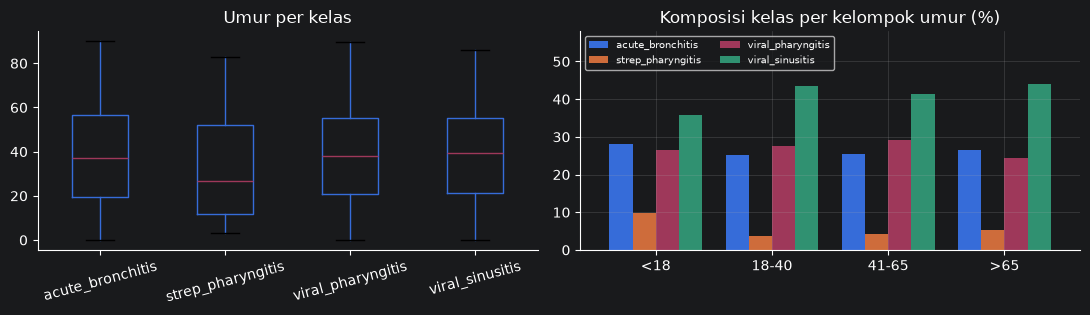

In [9]:
# # ===== 6. Demografi vs target =====
# def cramers_v(a, b):
#     ct = pd.crosstab(a, b)
#     return np.sqrt(chi2_contingency(ct)[0] / (ct.values.sum() * (min(ct.shape) - 1)))
#
# dm = train.merge(patients, on=PASIEN).assign(umur=lambda d: d["age_at_visit"].where(d["age_at_visit"] < 120),
#                                                marital=lambda d: d["marital_at_visit"].str[0])   # 'Married' dan 'M' dihitung sama
# hasil = []
# for c in ["gender", "race", "ethnicity", "marital", "county"]:
#     x = dm[c].astype(object).fillna("(kosong)")
#     hasil.append((c, "kategori", len(x.unique()), round(cramers_v(x, dm[TARGET]), 3), round(chi2_contingency(pd.crosstab(x, dm[TARGET]))[1], 4)))
# for c in ["umur"]:
#     hasil.append((c, "numerik", "-", np.nan, round(kruskal(*[d[c].dropna() for _, d in dm.groupby(TARGET)])[1], 4)))
# inc = pd.to_numeric(dm["income_at_visit"], errors="coerce")
# hasil.append(("income (yang terbaca angka)", "numerik", "-", np.nan, round(kruskal(*[inc[g.index].dropna() for _, g in dm.groupby(TARGET)])[1], 4)))
# print(pd.DataFrame(hasil, columns=["kolom", "tipe", "n_nilai", "Cramer_V", "p_value"]).to_string(index=False))
#
# print("\numur per kelas:"); print(dm.groupby(TARGET)["umur"].describe().round(1)[["count", "mean", "25%", "50%", "75%"]].to_string())
# dm["kel_umur"] = pd.cut(dm["umur"], [-0.1, 17.99, 40, 65, 120], labels=["<18", "18-40", "41-65", ">65"])
# print("\nproporsi kelas per kelompok umur:"); print(pd.crosstab(dm["kel_umur"], dm[TARGET], normalize="index").round(3).to_string())
#
# fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
# dm.boxplot(column="umur", by=TARGET, ax=ax[0], rot=15, grid=False); ax[0].set_title("Umur per kelas"); ax[0].set_xlabel(""); fig.suptitle("")
# pd.crosstab(dm["kel_umur"], dm[TARGET], normalize="index").mul(100).plot.bar(ax=ax[1], rot=0, width=.8)
# ax[1].set_title("Komposisi kelas per kelompok umur (%)"); ax[1].set_xlabel(""); ax[1].set_ylim(0, 58); ax[1].legend(fontsize=7, ncol=2, loc="upper left")
# plt.tight_layout(); plt.show()

**Temuan.**
- Tidak ada hubungan berarti untuk **gender, race, ethnicity, dan income** (p antara 0,14 dan 0,74). `county` punya V = 0,114 tetapi p = 0,886: V besar di sini hanya karena banyak kategori dengan sel kecil, bukan sinyal.
- **Umur** (p = 0,0009) dan **marital** (p = 0,005) berhubungan lemah. Strep paling muda: median 26,8 tahun versus 37–39 pada kelas lain, dan proporsinya 9,9% pada kelompok < 18 tahun dibanding 3,8–5,2% pada kelompok lain.
- *Dugaan:* hubungan marital dengan target sebagian besar hanya cerminan umur (marital kosong = anak dan remaja, lihat bagian 5). Dugaan ini belum diuji secara terkendali.

### 7. Kapan kunjungan terjadi, dan apakah waktu berhubungan dengan target?
Hubungan dibandingkan dengan *label yang diacak* (200 kali) untuk melihat berapa V yang muncul karena kebetulan.

C:\Users\hajar\AppData\Local\Temp\ipykernel_33204\2349537900.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  bw["bulan"], bw["jam"], bw["hari"], bw["ym"] = bw.prediction_time.dt.month, bw.prediction_time.dt.hour, bw.prediction_time.dt.dayofweek, bw.prediction_time.dt.to_period("M")


rentang:                             min                       max
split                                                    
test  2024-03-27 07:16:35+00:00 2026-10-29 07:40:32+00:00
train 2024-05-22 20:17:27+00:00 2026-10-31 19:05:32+00:00
KS train vs test pada waktu: p = 0.406
bulan : Cramer V asli 0.055 | label diacak: rata-rata 0.055, persentil-95 0.066
jam   : Cramer V asli 0.086 | label diacak: rata-rata 0.080, persentil-95 0.092
hari  : Cramer V asli 0.052 | label diacak: rata-rata 0.040, persentil-95 0.052


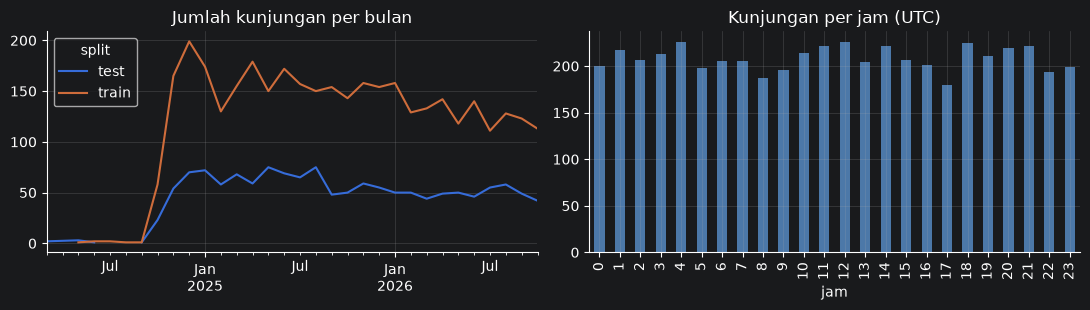

In [10]:
# # ===== 7. Waktu prediksi =====
# bw = base.assign(split=np.where(base[TARGET].notna(), "train", "test"))
# bw["bulan"], bw["jam"], bw["hari"], bw["ym"] = bw.prediction_time.dt.month, bw.prediction_time.dt.hour, bw.prediction_time.dt.dayofweek, bw.prediction_time.dt.to_period("M")
# print("rentang:", bw.groupby("split").prediction_time.agg(["min", "max"]).to_string())
# print("KS train vs test pada waktu: p =", round(ks_2samp(bw[bw.split == "train"].prediction_time.astype("int64"), bw[bw.split == "test"].prediction_time.astype("int64"))[1], 3))
#
# trw = bw[bw.split == "train"]; rng = np.random.RandomState(0)
# for c in ["bulan", "jam", "hari"]:
#     asli = cramers_v(trw[c], trw[TARGET]); acak = [cramers_v(trw[c], rng.permutation(trw[TARGET].values)) for _ in range(200)]
#     print(f"{c:6s}: Cramer V asli {asli:.3f} | label diacak: rata-rata {np.mean(acak):.3f}, persentil-95 {np.percentile(acak, 95):.3f}")
#
# fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
# bw.groupby(["ym", "split"]).size().unstack().plot(ax=ax[0]); ax[0].set_title("Jumlah kunjungan per bulan"); ax[0].set_xlabel("")
# bw.groupby("jam").size().plot.bar(ax=ax[1], color="#4C78A8"); ax[1].set_title("Kunjungan per jam (UTC)")
# plt.tight_layout(); plt.show()

**Temuan.**
- Jumlah kunjungan **sangat tidak merata**: hanya 14 kunjungan sebelum Oktober 2024, lalu melonjak (81 di Okt 2024, puncak 269 di Des 2024) dan menurun pelan menjadi ±155–172 per bulan di akhir 2026. Bentuk yang sama muncul pada train dan test (KS p = 0,41).
- Jam kunjungan hampir seragam.
- Bulan, jam, dan hari **tidak melampaui batas kebetulan** (V asli 0,055; 0,086; 0,052 versus persentil-95 acak 0,066; 0,092; 0,052). Hari tepat di batas, tidak meyakinkan.

### 8. Teks keluhan utama (`presenting_complaints`)

In [11]:
# ===== 8. presenting_complaints (teks pendek) =====
print("nilai unik:", complaints["presenting_complaints_text"].nunique())
print(complaints["presenting_complaints_text"].value_counts().head(12).to_string())
ck = complaints.merge(train[[KEY, TARGET]], on=KEY)
top = complaints["presenting_complaints_text"].value_counts().head(8).index
print("\nkomposisi kelas untuk 8 teks teratas (baris = teks, % per baris):")
print(pd.crosstab(ck["presenting_complaints_text"].where(ck["presenting_complaints_text"].isin(top), "(lainnya)"), ck[TARGET], normalize="index").mul(100).round(0).to_string())

nilai unik: 8
presenting_complaints_text
Reports: Cough, Throat symptoms           927
Reports: Cough, Fever, Throat symptoms    925
Reports: Throat symptoms                  861
Reports: Fever, Throat symptoms           758
Reports: Cough                            514
Reports: other respiratory complaints     406
Reports: Cough, Fever                     339
Reports: Fever                            270

komposisi kelas untuk 8 teks teratas (baris = teks, % per baris):
target_class                            acute_bronchitis  strep_pharyngitis  viral_pharyngitis  viral_sinusitis
presenting_complaints_text                                                                                     
Reports: Cough                                       5.0                0.0               15.0             80.0
Reports: Cough, Fever                               44.0                1.0               25.0             30.0
Reports: Cough, Fever, Throat symptoms              64.0                0.0 

**Temuan.** Hanya ada **8 teks unik** berformat "Reports: ...", jadi ini sebenarnya variabel kategori, bukan teks bebas. Hubungannya dengan target **kuat**:
- "Reports: Cough" → 80% sinusitis.
- "Reports: Cough, Fever, Throat symptoms" → 64% bronkitis.
- "Reports: Fever, Throat symptoms" → persentase strep tertinggi (16%).
- Strep hampir tidak pernah muncul pada teks yang memuat "Cough" (0–1%).

*Pertanyaan terbuka:* apakah teks ini sekadar ringkasan dari `triage_symptoms`, atau menambah informasi di luarnya? Belum diperiksa di sini.

### 9. `triage_vitals`: tabel long
Bagaimana strukturnya, apakah satuan dan formatnya seragam, dan seperti apa sebaran nilainya?

baris per encounter: {6: 5000} | tipe kolom value: object

nama vital x satuan (jumlah baris):
unit                 %  /min  beats/min  breaths/min  fraction  kPa  kg/m2  mmHg
vital_name                                                                      
BMI                  0     0          0            0         0    0   5000     0
Diastolic BP         0     0          0            0         0  317      0  4683
Heart rate           0  4333        667            0         0    0      0     0
Respiratory rate     0  4338          0          662         0    0      0     0
SpO2              4569     0          0            0       431    0      0     0
Systolic BP          0     0          0            0         0  301      0  4699

bentuk nilai (angka -> 9):
value
99.9      18555
999.9      4010
99.99      3196
9.99        456
999.99      246
9.9          85
99,99        85
9999.9       19

baris yang tetap tidak bisa dibaca sebagai angka: 3320

ringkasan per (vital, satuan):
       

C:\Users\hajar\AppData\Local\Temp\ipykernel_33204\1916203768.py:17: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(d["angka"].dropna(), vert=True); ax.set_title(f"{n} [{u}]", fontsize=8); ax.set_xticks([])
C:\Users\hajar\AppData\Local\Temp\ipykernel_33204\1916203768.py:17: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(d["angka"].dropna(), vert=True); ax.set_title(f"{n} [{u}]", fontsize=8); ax.set_xticks([])
C:\Users\hajar\AppData\Local\Temp\ipykernel_33204\1916203768.py:17: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(d["angka"].dropna(), vert=True); ax.set_title(f"{n} [{u}]", fontsize=8); ax.set_xticks([])
C:\Users\haja

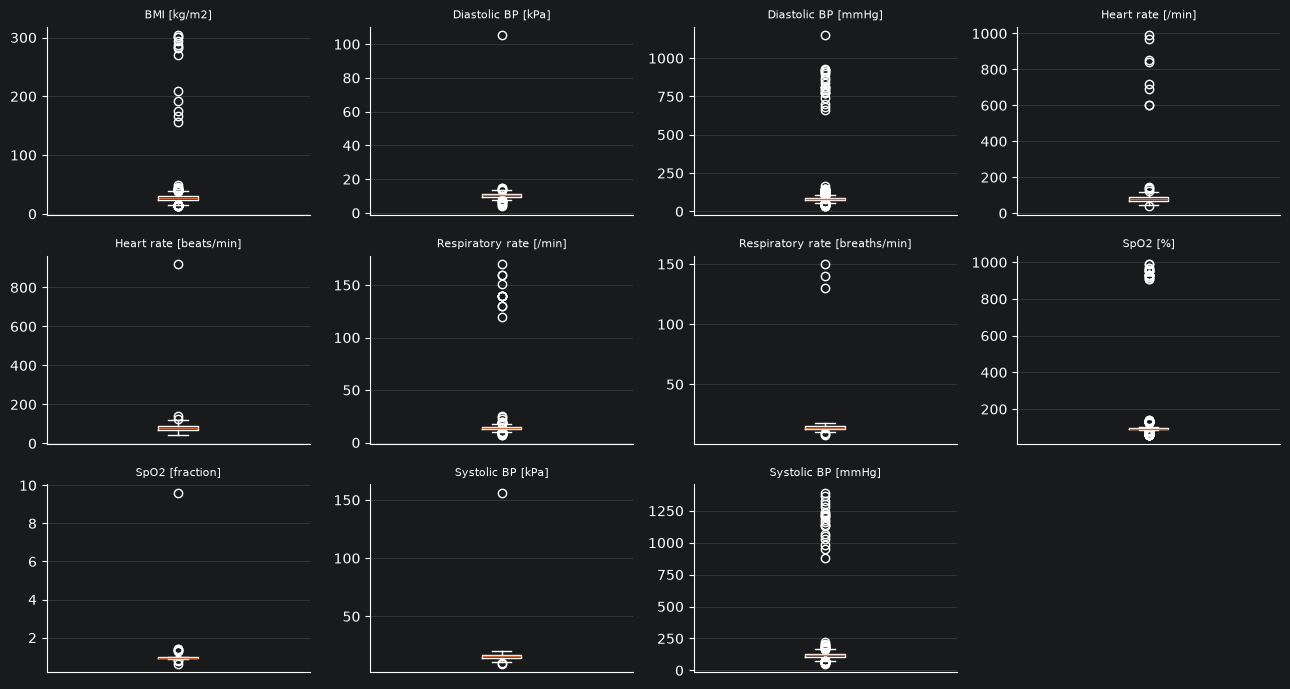

In [12]:
# ===== 9. triage_vitals: tabel long =====
print("baris per encounter:", vitals.groupby(KEY).size().value_counts().to_dict(), "| tipe kolom value:", vitals["value"].dtype)
print("\nnama vital x satuan (jumlah baris):"); print(pd.crosstab(vitals["vital_name"], vitals["unit"]).to_string())
print("\nbentuk nilai (angka -> 9):"); print(bentuk(vitals["value"]).value_counts().head(8).to_string())
vitals["angka"] = pd.to_numeric(vitals["value"].astype(str).str.replace(",", ".", regex=False), errors="coerce")
print("\nbaris yang tetap tidak bisa dibaca sebagai angka:", int(vitals["angka"].isna().sum()))
print("\nringkasan per (vital, satuan):")
print(vitals.groupby(["vital_name", "unit"])["angka"].describe(percentiles=[.01, .5, .99]).round(1)[["count", "min", "1%", "50%", "99%", "max"]].to_string())

ekstrem = vitals["angka"] > 5 * vitals.groupby(["vital_name", "unit"])["angka"].transform("median")
print("\nnilai > 5x median kelompoknya (vital, satuan):", int(ekstrem.sum()), "| per vital:", vitals[ekstrem].groupby("vital_name").size().to_dict())
print("contoh nilai ekstrem:", vitals.loc[ekstrem, ["vital_name", "unit", "value"]].head(6).values.tolist())

g = vitals.groupby(["vital_name", "unit"])
fig, axs = plt.subplots(3, 4, figsize=(13, 7))
for ax, ((n, u), d) in zip(axs.ravel(), g):
    ax.boxplot(d["angka"].dropna(), vert=True); ax.set_title(f"{n} [{u}]", fontsize=8); ax.set_xticks([])
for ax in axs.ravel()[len(g):]: ax.axis("off")
plt.tight_layout(); plt.show()

**Temuan.**
- Struktur: tepat 6 vital (BMI, HR, RR, SpO2, tekanan sistolik, diastolik) per encounter. Kolom `value` bertipe **teks**; 112 nilai memakai **koma desimal** (`28,02`). Setelah koma diganti titik semua nilai terbaca; 3.320 NaN yang tersisa adalah baris yang memang kosong (BMI 1.886, vital lain 263–308).
- **Satuan campur:** tekanan darah dalam mmHg dan kPa (nilai ±10–16 itu kPa, bukan mmHg); SpO2 dalam % dan fraction (±0,9–1,0); HR dan RR punya dua penulisan satuan yang artinya sama (`/min` vs `beats/min`, `/min` vs `breaths/min`).
- **Nilai ekstrem:** 103 nilai lebih dari 5× median kelompoknya, mis. HR 600, SpO2 970, tekanan sistolik 1.200, BMI 288. Polanya seperti nilai normal yang terkali 10 (RR 120 untuk 12), yaitu kesalahan penempatan desimal, dan bukan kondisi klinis nyata.

### 10. Apakah vital berhubungan dengan target?
Dibandingkan hanya pada satuan dominan per vital (agar skala tidak bercampur), dengan nilai di luar persentil 1–99 dibuang.

In [13]:
# ===== 10. Vital vs target (hanya satuan yang dominan per vital, agar tidak mencampur skala) =====
dom = vitals.groupby("vital_name")["unit"].agg(lambda s: s.value_counts().index[0])
vd = vitals[vitals["unit"] == vitals["vital_name"].map(dom)].merge(train[[KEY, TARGET]], on=KEY)
vd = vd[vd["angka"].between(vd.groupby("vital_name")["angka"].transform(lambda s: s.quantile(.01)), vd.groupby("vital_name")["angka"].transform(lambda s: s.quantile(.99)))]
print("satuan dominan:", dom.to_dict(), "| nilai di luar persentil 1-99 dibuang untuk perbandingan ini")
print("\nmedian per kelas:"); print(vd.pivot_table(index="vital_name", columns=TARGET, values="angka", aggfunc="median").round(1).to_string())
print("\nKruskal-Wallis p per vital:")
print({n: float(f"{kruskal(*[x['angka'].values for _, x in d.groupby(TARGET)])[1]:.3g}") for n, d in vd.groupby("vital_name")})
terisi = vitals.dropna(subset=["angka"]).groupby(KEY)["vital_name"].nunique().reindex(base[KEY]).fillna(0).astype(int)
print("\njumlah vital BERNILAI (dari 6) per encounter:", terisi.value_counts().sort_index().to_dict())
print("nilai kosong per vital:", vitals[vitals["angka"].isna()].groupby("vital_name").size().to_dict())
bmi = vitals[vitals["vital_name"] == "BMI"].merge(patients[[PASIEN, "age_at_visit"]], on=PASIEN)
bmi = bmi[(bmi["age_at_visit"] < 120) & bmi["angka"].between(10, 80)]
print("korelasi Spearman BMI vs umur:", round(bmi["angka"].corr(bmi["age_at_visit"], method="spearman"), 3))

satuan dominan: {'BMI': 'kg/m2', 'Diastolic BP': 'mmHg', 'Heart rate': '/min', 'Respiratory rate': '/min', 'SpO2': '%', 'Systolic BP': 'mmHg'} | nilai di luar persentil 1-99 dibuang untuk perbandingan ini

median per kelas:
target_class      acute_bronchitis  strep_pharyngitis  viral_pharyngitis  viral_sinusitis
vital_name                                                                               
BMI                           27.8               26.8               27.8             27.8
Diastolic BP                  79.0               78.5               79.0             80.0
Heart rate                    80.0               80.0               80.0             80.0
Respiratory rate              14.0               14.0               14.0             14.0
SpO2                          94.0               94.0               94.0             94.0
Systolic BP                  117.0              118.0              118.0            118.0

Kruskal-Wallis p per vital:
{'BMI': 0.000329, 'Diastoli

**Temuan.**
- Median HR, RR, SpO2, dan tekanan darah **nyaris identik** antar kelas (p antara 0,19 dan 0,96).
- Hanya **BMI** yang menonjol (p = 0,0003; strep 26,8 vs 27,8). Namun BMI berkorelasi kuat dengan umur (Spearman 0,60), dan strep lebih muda (bagian 6), jadi perbedaan ini kemungkinan besar efek umur (dugaan).
- Kelengkapan: hanya **2.345 dari 5.000** encounter yang punya keenam vital bernilai; BMI paling sering kosong (38%).

### 11. `triage_symptoms`: nama gejala
Berapa nama gejala yang berbeda, dan apakah ada yang sebenarnya sama?

In [14]:
# ===== 11. triage_symptoms: nama gejala =====
print("baris per encounter:", symptoms.groupby(KEY).size().describe().round(1)[["min", "50%", "max"]].to_dict())
print("nama unik mentah:", symptoms["symptom_concept"].nunique(), "| setelah strip + huruf kecil:", symptoms["symptom_concept"].str.strip().str.lower().nunique())
sym = symptoms.assign(nama=symptoms["symptom_concept"].str.strip().str.lower())
print("\nsemua nama (diurutkan, dengan jumlah):")
frek = sym["nama"].value_counts()
print(", ".join(f"{k} ({v})" for k, v in sorted(frek.items())))
print("\nencounter yang namanya muncul > 1x dalam satu encounter:", int(sym.duplicated([KEY, "nama"]).sum()), "baris")
print("apakah observed_at sama dalam satu encounter?", bool((symptoms.groupby(KEY)["observed_at"].nunique() == 1).all()))

baris per encounter: {'min': 1.0, '50%': 4.0, 'max': 12.0}
nama unik mentah: 118 | setelah strip + huruf kecil: 70

semua nama (diurutkan, dengan jumlah):
airway secretions (205), anxiety (2), blocked nose (266), blurred vision (55), body malaise (315), breast/nipple pain (2), breathing discomfort (113), chest pain (3), cognitive difficulties (9), confusion (30), constipation (2), cough (1345), cough / productive (315), cough symptom (344), coughing (341), decreased attentiveness (29), decreased communication (31), decreased in judgement (30), decreased visual perception (32), delayed verbal/language skills (9), difficulty breathing (116), dyspnea/wheeze (615), ear pressure (30), febrile feeling (267), feeling unwell (247), fever (1203), feverish (270), frequent urination (216), general fatigue symptoms (271), general malaise (274), head and facial symptoms (1542), hunger (189), itching (26), joint pain (14), joint redness (5), joint stiffness (1), joint swelling (5), memory loss (28),

**Temuan.**
- Ada **118 nama mentah** yang menjadi **70** setelah merapikan spasi dan huruf besar/kecil.
- Dari daftar terlihat banyak nama yang **bersinonim**: *cough, coughing, persistent cough, cough symptom, cough / productive*; *fever, feverish, raised temperature, febrile feeling, temperature complaint*; *throat symptoms, throat pain, sore throat, throat discomfort, painful swallowing*; dan seterusnya.
- Ada juga gejala yang jarang dan tidak bersifat pernapasan (*frequent urination, thirst, hunger, confusion, blurred vision*, dll.).
- 13 baris adalah nama yang berulang dalam satu encounter. `observed_at` **sama** untuk semua gejala dalam satu encounter, jadi tidak ada urutan waktu.

### 12. Apakah gejala berhubungan dengan target?
% encounter yang memiliki tiap gejala, per kelas (18 nama paling sering).

% encounter yang memiliki gejala tsb, per kelas (18 nama teratas):
target_class              acute_bronchitis  strep_pharyngitis  viral_pharyngitis  viral_sinusitis
throat symptoms                       40.0               41.0               41.0             30.0
head and facial symptoms              10.0                6.0                8.0             63.0
systemic symptoms                     56.0               37.0               39.0              2.0
cough                                 34.0                2.0               24.0             28.0
nasal symptoms                        42.0               26.0               29.0             12.0
fever                                 42.0               27.0               26.0             11.0
respiratory secretions                38.0                9.0                9.0             25.0
dyspnea/wheeze                        31.0                3.0                6.0              7.0
painful swallowing                    11.0         

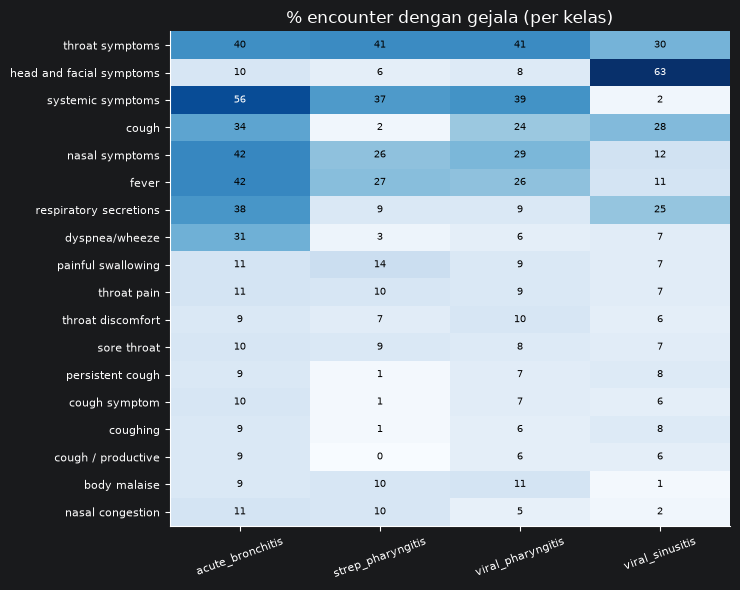

In [15]:
# ===== 12. Gejala vs target: nama yang paling sering =====
pres = sym.drop_duplicates([KEY, "nama"]).assign(v=1).pivot_table(index=KEY, columns="nama", values="v", fill_value=0)
top = frek.head(18).index
M = pres[top].join(kelas_enc, how="inner")
tab = M.groupby(TARGET)[list(top)].mean().mul(100).round(0).T
print("% encounter yang memiliki gejala tsb, per kelas (18 nama teratas):"); print(tab.to_string())
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(tab.values, cmap="Blues", aspect="auto"); ax.set_xticks(range(4)); ax.set_xticklabels(tab.columns, rotation=20, fontsize=8)
ax.set_yticks(range(len(tab))); ax.set_yticklabels(tab.index, fontsize=8); ax.grid(False)
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]): ax.text(j, i, int(tab.values[i, j]), ha="center", va="center", fontsize=7, color="white" if tab.values[i, j] > 50 else "black")
ax.set_title("% encounter dengan gejala (per kelas)"); plt.tight_layout(); plt.show()

**Temuan.** Pola **kuat** dan masuk akal secara klinis:
- *head and facial symptoms*: 63% pada sinusitis vs 6–10% pada kelas lain.
- *systemic symptoms*: hanya 2% pada sinusitis vs 37–56%.
- *dyspnea/wheeze*: 31% pada bronkitis vs 3–7%.
- *cough*: hanya 2% pada strep vs 24–34%.

Karena sinonim terpecah ke banyak nama (mis. lima varian batuk, masing-masing hanya 5–10%), sinyalnya tersebar. *Dugaan:* menyatukan sinonim akan memusatkan sinyal ini.

### 13. Apakah urutan baris gejala bermakna?
Tabel long tidak punya kolom urutan, tetapi baris tersimpan dalam urutan tertentu. Apakah gejala yang tercatat **pertama** berbeda antar kelas?

In [16]:
# ===== 13. Urutan baris gejala dalam satu encounter: bermakna? =====
# Tabel long tidak punya kolom urutan, tetapi baris tersimpan dalam urutan tertentu. Apakah gejala yang tercatat PERTAMA berbeda antar kelas?
sym["pos"] = sym.groupby(KEY).cumcount()
pertama = sym[sym["pos"] == 0].merge(train[[KEY, TARGET]], on=KEY)
top_p = pertama["nama"].value_counts().head(8).index
print("% gejala pertama per kelas (baris = nama, 8 teratas):")
print(pd.crosstab(pertama["nama"].where(pertama["nama"].isin(top_p), "(lainnya)"), pertama[TARGET], normalize="columns").mul(100).round(0).to_string())
print("\nCramer V (gejala pertama vs target):", round(cramers_v(pertama["nama"], pertama[TARGET]), 3))
p0 = sym[sym["pos"] == 0]
print("gejala pertama, 5 teratas (%)  train:", p0.merge(train[[KEY]], on=KEY)["nama"].value_counts(normalize=True).head(5).mul(100).round(1).to_dict())
print("gejala pertama, 5 teratas (%)  test :", p0.merge(test[[KEY]], on=KEY)["nama"].value_counts(normalize=True).head(5).mul(100).round(1).to_dict())

% gejala pertama per kelas (baris = nama, 8 teratas):
target_class              acute_bronchitis  strep_pharyngitis  viral_pharyngitis  viral_sinusitis
nama                                                                                             
(lainnya)                             24.0               63.0               34.0             20.0
cough                                 34.0                2.0               24.0             27.0
cough / productive                     9.0                0.0                6.0              6.0
cough symptom                         10.0                1.0                7.0              6.0
coughing                               9.0                1.0                6.0              7.0
fever                                  5.0               24.0               12.0              5.0
head and facial symptoms               0.0                0.0                0.0             19.0
nasal symptoms                         1.0                9.0   

**Temuan.** Ya, dan sangat jelas: Cramér's V gejala pertama terhadap target = **0,402**, jauh di atas variabel demografi dan waktu (semuanya ≤ 0,11, dan sebagian besar itu pun hanya kebetulan).
- Pada strep, 63% gejala pertama berada di luar 8 nama teratas (fever 24%, nasal symptoms 9%).
- Pada sinusitis, 19% diawali *head and facial symptoms*, sedangkan pada kelas lain 0%.
- Distribusi gejala pertama di test mirip train (cough 25,6% vs 26,6%), jadi pola ini ada di kedua bagian data.

**Catatan penting:** urutan baris adalah **artefak cara data disimpan**, bukan informasi klinis (waktu pencatatan identik). Apakah sah memanfaatkannya adalah keputusan pemodelan yang harus dijelaskan terbuka di laporan, dan jangan diklaim sebagai temuan medis.

### 14. `triage_symptom_severity`

encounter dicakup: 4961 dari 5000 | skor kosong: 765
{'count': 15829.0, 'mean': 40.4, 'std': 19.9, 'min': 0.0, '25%': 27.0, '50%': 39.0, '75%': 53.0, 'max': 100.0}

pasangan (encounter, gejala) di severity yang ada di triage_symptoms: 100.0 %
pasangan di triage_symptoms yang punya skor severity: 87.1 %
nama yang ada di symptoms tetapi tidak pernah di severity (jumlah baris): {'dyspnea/wheeze': 615, 'difficulty breathing': 116, 'breathing discomfort': 113, 'wheezy feeling': 109, 'shortness of breath / wheeze': 104, 'sweating': 1}


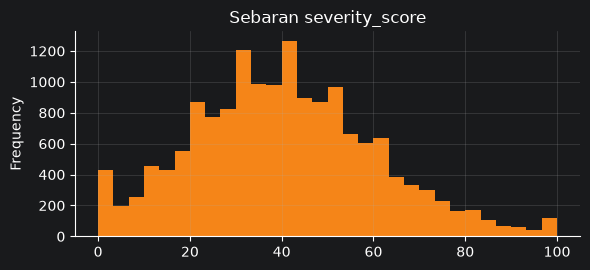

In [17]:
# ===== 14. triage_symptom_severity =====
print("encounter dicakup:", severity[KEY].nunique(), "dari", len(base), "| skor kosong:", int(severity["severity_score"].isna().sum()))
print(severity["severity_score"].describe().round(1).to_dict())
sv = severity.assign(nama=severity["symptom_concept"].str.strip().str.lower())
pair_sym, pair_sv = set(zip(sym[KEY], sym["nama"])), set(zip(sv[KEY], sv["nama"]))
print("\npasangan (encounter, gejala) di severity yang ada di triage_symptoms:", round(len(pair_sv & pair_sym) / len(pair_sv) * 100, 1), "%")
print("pasangan di triage_symptoms yang punya skor severity:", round(len(pair_sv & pair_sym) / len(pair_sym) * 100, 1), "%")
print("nama yang ada di symptoms tetapi tidak pernah di severity (jumlah baris):",
      sym[~sym["nama"].isin(set(sv["nama"]))]["nama"].value_counts().head(6).to_dict())
ax = severity["severity_score"].plot.hist(bins=30, figsize=(6, 2.8), color="#F58518"); ax.set_title("Sebaran severity_score")
plt.tight_layout(); plt.show()

**Temuan.**
- Mencakup 4.961 encounter; 15.829 skor terisi dari 16.594 baris (765 kosong, 4,6%).
- Semua pasangan (encounter, gejala) di tabel ini ada di `triage_symptoms` (100%), tetapi hanya **87,1%** gejala punya skor. Yang tidak pernah punya skor adalah kelompok dyspnea/wheeze (1.057 baris dari lima nama) dan satu baris *sweating*.
- Skor berada di 0–100 (rata-rata 40,4) dengan tumpukan di kedua ujung, kemungkinan akibat dipotong di batas (dugaan).

### 15. Tabel riwayat: apakah semua kejadian terjadi **sebelum** waktu prediksi?
Selisih = `prediction_time` dikurangi waktu catatan. Selisih negatif berarti catatan itu dari masa depan (risiko kebocoran).

In [18]:
# ===== 15. Tabel riwayat: apakah semua kejadian terjadi SEBELUM waktu prediksi? =====
waktu_kol = {"previous_encounter": "history_start", "conditions": "recorded_at", "observations": "observed_at", "medications": "recorded_at",
             "procedures": "recorded_at", "immunizations": "recorded_at", "allergies": "recorded_at"}
pt = base.set_index(PASIEN)["prediction_time"]
ringkas = []
for n, kol in waktu_kol.items():
    d = hist[n].copy(); d["t"] = pd.to_datetime(d[kol], utc=True, format="mixed")
    d["selisih_hari"] = (d[PASIEN].map(pt) - d["t"]).dt.total_seconds() / 86400
    ringkas.append({"tabel": n, "baris": len(d), "pasien": d[PASIEN].nunique(), "%pasien": round(d[PASIEN].nunique() / len(base) * 100, 1),
                    "baris/pasien": d.groupby(PASIEN).size().median(),
                    "hari_median": round(d["selisih_hari"].median(), 0), "hari_maks": round(d["selisih_hari"].max(), 0),
                    "setelah": int((d["selisih_hari"] < 0).sum()), "tepat": int((d["selisih_hari"] == 0).sum()),
                    "<1jam": int((d["selisih_hari"] < 1/24).sum()), "<1hari": int((d["selisih_hari"] < 1).sum()),
                    "pasien<1hari": d.loc[d["selisih_hari"] < 1, PASIEN].nunique()})
print(pd.DataFrame(ringkas).set_index("tabel").to_string())
o = hist["observations"].copy(); o["gap"] = (o[PASIEN].map(pt) - pd.to_datetime(o["observed_at"], utc=True, format="mixed")).dt.total_seconds() / 86400
dekat = o.loc[o["gap"] < 1, PASIEN].unique()
kd = kelas_pasien.reindex(dekat).dropna()
print(f"\npasien train dengan observasi < 1 hari sebelum prediksi: n = {len(kd)} | komposisi kelas:", kd.value_counts(normalize=True).round(2).to_dict())
print("komposisi kelas seluruh train (pembanding):", kelas_pasien.value_counts(normalize=True).round(2).to_dict())
print("\nketerangan: hari_* = selisih (prediction_time - waktu catatan) dalam hari; setelah/tepat = baris yang terjadi sesudah/tepat saat prediksi; <1jam & <1hari = baris yang sangat dekat sebelum prediksi")

                    baris  pasien  %pasien  baris/pasien  hari_median  hari_maks  setelah  tepat  <1jam  <1hari  pasien<1hari
tabel                                                                                                                        
previous_encounter   4471    4471     89.4           1.0         56.0      365.0        0      0      1      67            67
conditions           3583    2222     44.4           1.0         48.0      365.0        0      0      0      58            27
observations        55648    1895     37.9          33.0          7.0      364.0        0      0     76    1160            55
medications          3467    2001     40.0           1.0         38.0      365.0        0      0      3      46            30
procedures          17024    3111     62.2           6.0         29.0      365.0        0      0      8     251            67
immunizations        1802    1314     26.3           1.0         40.0      364.0        0      0      0      32       

**Temuan.**
- **Tidak ada** catatan setelah maupun tepat pada `prediction_time` di tabel mana pun. Jendela riwayat tampak ±365 hari ke belakang (maksimum 364–365 hari).
- Sebagian kecil catatan sangat dekat dengan waktu prediksi: mis. di `observations` 1.160 baris (milik 55 pasien) dalam < 1 hari dan 76 baris dalam < 1 jam; pasien yang terdampak < 2% dari 5.000.
- Dari 40 pasien train yang punya observasi < 1 hari, 65% berkelas sinusitis (dasar 41%), tetapi sampelnya terlalu kecil untuk disimpulkan (angka ini dihitung di bagian bawah tabel).

### 16. Apakah punya/tidaknya riwayat berbeda antar kelas?

% pasien yang punya >= 1 baris riwayat, per kelas:
                    acute_bronchitis  strep_pharyngitis  viral_pharyngitis  viral_sinusitis  p_chi2
tabel                                                                                              
previous_encounter              91.1               89.2               88.3             89.1   0.247
conditions                      48.5               37.9               40.0             43.3   0.001
observations                    46.6               34.9               32.2             35.3   0.000
medications                     40.3               35.4               39.8             40.1   0.629
procedures                      63.7               64.1               58.7             63.0   0.080
immunizations                   29.7               25.1               22.7             25.2   0.006
allergies                        0.0                0.0                0.0              0.0     NaN


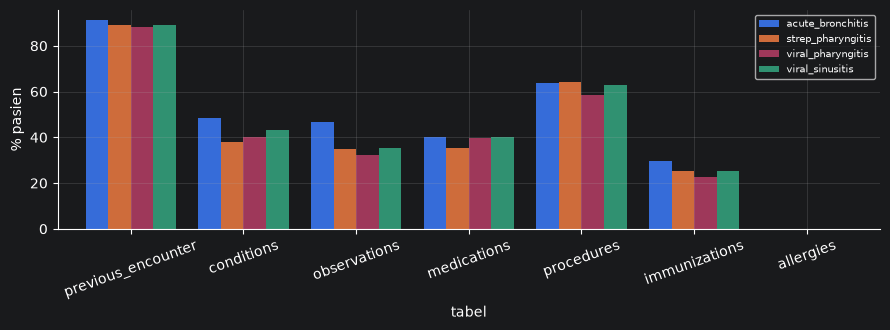

In [19]:
# ===== 16. Riwayat vs target: apakah punya/tidaknya riwayat berbeda antar kelas? =====
rows = []
for n in hist:
    ada = base[PASIEN].isin(set(hist[n][PASIEN]))
    t = base.assign(ada=ada).dropna(subset=[TARGET])
    pr = t.groupby(TARGET)["ada"].mean().mul(100).round(1)
    rows.append({"tabel": n, **pr.to_dict(), "p_chi2": round(chi2_contingency(pd.crosstab(t["ada"], t[TARGET]))[1], 3) if t["ada"].nunique() > 1 else np.nan})
cov = pd.DataFrame(rows).set_index("tabel")
print("% pasien yang punya >= 1 baris riwayat, per kelas:"); print(cov.to_string())
ax = cov.drop(columns="p_chi2").plot.bar(figsize=(9, 3.4), rot=20, width=.8); ax.set_ylabel("% pasien"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Temuan.** Persentase pasien yang punya riwayat berbeda **antar kelas** pada `conditions` (p = 0,001), `observations` (p < 0,001), dan `immunizations` (p = 0,006): pasien bronkitis paling sering punya riwayat (observations 46,6% vs 32–35%; conditions 48,5% vs 38–43%). Untuk `previous_encounter`, `medications`, dan `procedures` perbedaannya tidak meyakinkan (p ≥ 0,08).
Ini 7 uji sekaligus, dan belum diketahui apakah sebabnya umur atau hal lain (pertanyaan terbuka).

### 17. Isi tabel riwayat: kolom teks dan kategori

In [20]:
# ===== 17. Isi tabel riwayat: kolom teks & kategori =====
for n, kol in [("conditions", "condition_name"), ("medications", "medication_name"), ("procedures", "procedure_name"),
               ("immunizations", "immunization_name"), ("previous_encounter", "history_type")]:
    s = hist[n][kol]
    print(f"[{n}.{kol}] unik {s.nunique()} | unik huruf-kecil {s.str.lower().nunique()} | kosong {s.isna().mean()*100:.1f}%")
    print("   teratas:", s.value_counts().head(4).to_dict())
o = hist["observations"]
print("\nobservations: kategori x tipe nilai"); print(pd.crosstab(o["category"], o["value_type"]).to_string())
print("observation_name unik:", o["observation_name"].nunique(), "| paling sering:", o["observation_name"].value_counts().head(5).to_dict())
print("\nhistory_encounter_id: jumlah unik per tabel, dan yang ada di previous_encounter")
prev_ids = set(hist["previous_encounter"]["history_encounter_id"])
print({n: (hist[n]["history_encounter_id"].nunique(), round(hist[n]["history_encounter_id"].isin(prev_ids).mean() * 100, 1)) for n in hist if n != "previous_encounter"})

[conditions.condition_name] unik 207 | unik huruf-kecil 167 | kosong 5.3%
   teratas: {'Medication review due (situation)': 806, 'Stress (finding)': 324, 'Full-time employment (finding)': 287, 'Part-time employment (finding)': 201}
[medications.medication_name] unik 280 | unik huruf-kecil 200 | kosong 9.3%
   teratas: {'sodium fluoride 0.0272 MG/MG Oral Gel': 382, 'lisinopril 10 MG Oral Tablet': 231, 'Hydrochlorothiazide 25 MG Oral Tablet': 196, 'amLODIPine 2.5 MG Oral Tablet': 179}
[procedures.procedure_name] unik 595 | unik huruf-kecil 429 | kosong 4.3%
   teratas: {'Depression screening (procedure)': 1575, 'Assessment of health and social care needs (procedure)': 925, 'Removal of supragingival plaque and calculus from all teeth using dental instrument (procedure)': 840, 'Dental care (regime/therapy)': 832}
[immunizations.immunization_name] unik 55 | unik huruf-kecil 42 | kosong 7.9%
   teratas: {'Influenza  split virus  trivalent  PF': 1065, 'Td (adult)  5 Lf tetanus toxoid  preserv

**Temuan.**
- Nama klinis memakai **kapitalisasi tak konsisten**: jumlah nama unik menyusut setelah huruf kecil (conditions 207 → 167, medications 280 → 200, procedures 595 → 429, immunizations 55 → 42). Nama kosong 4–9%.
- `observations` sangat beragam: 547 jenis observasi, terbanyak kategori *survey* (26.020 baris, 85% bertipe teks), *laboratory* (14.553) dan *vital-signs* (13.246, semuanya numerik). `unit` kosong pada 90,5% baris bertipe teks (wajar, teks tidak punya satuan).
- Setiap pasien punya **satu** kunjungan sebelumnya (`previous_encounter` 1 baris/pasien), dan semua catatan klinis lain menempel pada kunjungan itu (100% `history_encounter_id` cocok).

## Ringkasan EDA

**Struktur.** Satu sampel = satu pasien = satu encounter (terbukti 1:1); train 3.600 dan test 1.400 tanpa pasien yang sama, dan keduanya tampak seragam. Tabel triase berbentuk long, tabel riwayat tidak lengkap untuk sebagian pasien (wajar), dan tidak ada catatan riwayat dari masa depan.

**Target.** Empat kelas dengan ketidakseimbangan 7,6:1 (strep hanya 5,4%); akurasi tidak cukup sebagai ukuran.

**Masalah kualitas data yang ditemukan.**
- Umur 999 (19 baris); income dalam 5 format; marital ditulis dua cara.
- Vitals: koma desimal (112), satuan campur (kPa/mmHg, fraction/%), nilai ekstrem akibat salah desimal (103), 11% nilai kosong.
- Nama gejala: 118 varian mentah yang bersinonim; severity tidak ada untuk kelompok dyspnea.
- Duplikat persis di observations, procedures, dan medications; nama klinis dengan kapitalisasi tak konsisten.

**Di mana sinyalnya.**

| sumber | kekuatan hubungan dengan target |
|---|---|
| gejala triase (khususnya head/facial, systemic, dyspnea, cough) | kuat |
| teks keluhan utama (8 kategori) | kuat |
| urutan baris gejala (gejala pertama) | sangat kuat (V = 0,40), tetapi **artefak data** |
| umur | sedang (strep lebih muda) |
| ada/tidaknya riwayat (conditions, observations, immunizations) | lemah |
| gender, race, ethnicity, income, county, waktu kunjungan, vitals (kecuali BMI~umur) | tidak berbeda dari kebetulan |

**Pertanyaan terbuka untuk tahap berikutnya.**
1. Apakah teks keluhan utama menambah informasi di luar gejala triase?
2. Apakah perbedaan riwayat antar kelas hanya efek umur?
3. Bagaimana memperlakukan sinonim gejala, satuan vital yang campur, dan nilai ekstrem?
4. Bagaimana menjelaskan dan menimbang penggunaan urutan baris gejala dalam laporan?